# Healthcare Analytics for Doctor Visits

**TIRTC Program (extension of the AICTE 4-week programme to 8 weeks) – Project P2**

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Statsmodels

## 1. Problem Statement
Why do some people visit a doctor more often than others? The dataset holds 5,190 people with their health condition, financial background, healthcare coverage and the number of doctor visits. The aim is to find which factors are associated with doctor visits and which of those associations survive once other factors are taken into account.

## 2. Objectives
- Understand the structure and quality of the data.
- Describe the pattern of doctor visits (the outcome).
- Compare visits across health, demographic, financial and coverage groups.
- Test whether the differences are larger than chance.
- Check which associations remain after adjusting for the other variables.
- Report findings with their limitations. Associations are not causes.

## 3. Dataset
`doctor_visits.csv` – 5,190 records, 13 columns (one is a record number). Column meaning is taken from the project's *Dataset Understanding Guide*. Two details come from the data itself, not the guide: `age` has only 12 distinct values, and `nchronic` and `lchronic` are mutually exclusive (checked in Section 4).

## Import libraries

In [1]:
import os, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)

os.makedirs("figures", exist_ok=True)

def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")

def table_image(tbl, name, fontsize=10, figsize=(10, 4), col_widths=None):
    # Renders a DataFrame as an image so it can be used on a slide.
    fig, ax = plt.subplots(figsize=figsize)
    ax.axis("off")
    t = ax.table(cellText=tbl.values, colLabels=tbl.columns, cellLoc="center", loc="center")
    t.auto_set_font_size(False)
    t.set_fontsize(fontsize)
    t.scale(1, 1.5)
    if col_widths:
        for j, w in enumerate(col_widths):
            for i in range(len(tbl) + 1):
                t[(i, j)].set_width(w)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor("#BBBBBB")
        if r == 0:
            cell.set_facecolor("#1F4E79")
            cell.set_text_props(color="white", weight="bold")
        elif r % 2 == 0:
            cell.set_facecolor("#EAF1F8")
    plt.tight_layout()
    save_fig(name)
    plt.show()

## Load the dataset

In [2]:
# Keep the CSV in the same folder as this notebook (or in /content/ on Colab).
candidates = ["doctor_visits.csv", "/content/doctor_visits.csv",
              "1776250375-P2-Healthcare_Analytics_for_Doctor_Visits__1_.csv"]
file_path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5190, 13)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


## 4. Understand the data

In [3]:
print("Column names:")
print(df.columns.tolist())
print()
df.info()

Column names:
['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

<class 'pandas.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   str    
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   str    
 9   freepoor    5190 non-null   str    
 10  freerepat   5190 non-null   str    
 11  nchronic    5190 non-null   str    
 12  lchronic    5190 non-null   str    
dtypes: float64(2), int64(5), str(6)
memory usage: 527.2 KB


In [4]:
display(df.describe().T.round(3))
display(df.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,5190.0,2595.500,1498.368,1.00,1298.25,2595.50,3892.75,5190.00
visits,5190.0,0.302,0.798,0.00,0.00,0.00,0.00,9.00
age,5190.0,0.406,0.205,0.19,0.22,0.32,0.62,0.72
income,5190.0,0.583,0.369,0.00,0.25,0.55,0.90,1.50
illness,5190.0,1.432,1.384,0.00,0.00,1.00,2.00,5.00
reduced,5190.0,0.862,2.888,0.00,0.00,0.00,0.00,14.00
health,5190.0,1.218,2.124,0.00,0.00,0.00,2.00,12.00


,count,unique,top,freq
gender,5190,2,female,2702
private,5190,2,no,2892
freepoor,5190,2,no,4968
freerepat,5190,2,no,4099
nchronic,5190,2,no,3098
lchronic,5190,2,no,4585


## 5. Data quality: missing values, duplicates, odd values

In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "None – no column has missing values")
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate record numbers:", df["Unnamed: 0"].duplicated().sum())

print("\nDistinct age values:", sorted(df["age"].unique()))
print("Rows with reduced = 14 (the maximum):", (df["reduced"] == 14).sum(),
      "| rows with reduced 9-13:", df["reduced"].between(9, 13).sum())
print("\nnchronic x lchronic:")
display(pd.crosstab(df["nchronic"], df["lchronic"]))

Missing values per column:
None – no column has missing values

Duplicate rows: 0
Duplicate record numbers: 0

Distinct age values: [np.float64(0.19), np.float64(0.22), np.float64(0.27), np.float64(0.32), np.float64(0.37), np.float64(0.42), np.float64(0.47), np.float64(0.52), np.float64(0.57), np.float64(0.62), np.float64(0.67), np.float64(0.72)]
Rows with reduced = 14 (the maximum): 188 | rows with reduced 9-13: 32

nchronic x lchronic:


lchronic,no,yes
nchronic,,
no,2493,605
yes,2092,0


**Observation**
- **Fact:** no missing values and no duplicate rows, so no cleaning was needed. Nothing was imputed or dropped.
- **Fact:** `age` takes only 12 values (0.19 to 0.72 in steps of 0.03 to 0.05). It looks like age ÷ 100, grouped into bands. This is an **assumption**; the guide only says "age value". Income (0 to 1.5) is probably scaled the same way, so only relative comparisons are made.
- **Fact:** `nchronic = yes` and `lchronic = yes` never occur together (2,092 and 605 records; 0 overlap). They are two separate categories, not "has a chronic condition" twice, so the guide's wording for them is unreliable.
- **Fact:** `reduced` stops at 14, and 188 records sit at 14 against only 32 records at 9 to 13 combined. **Hypothesis:** 14 is a cap meaning "14 or more" or the whole period.

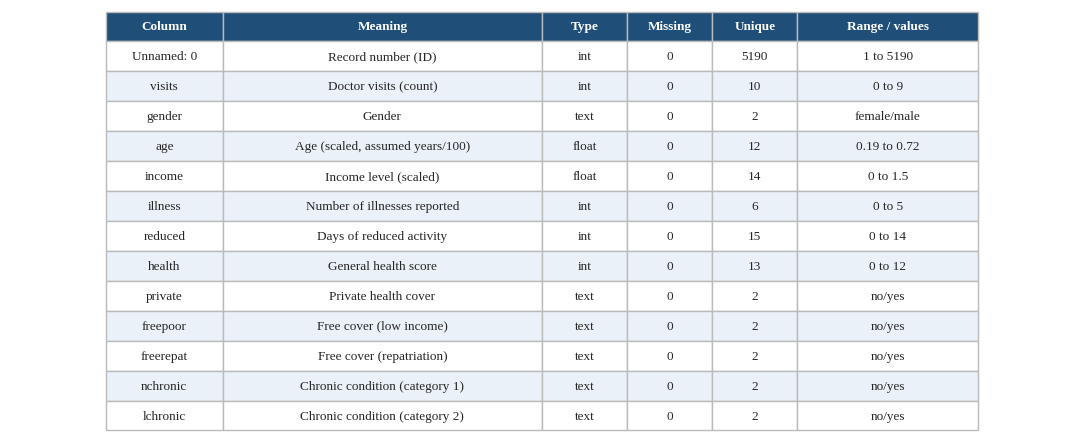

In [6]:
# Data dictionary image (for the presentation)
meaning = {
    "Unnamed: 0": "Record number (ID)", "visits": "Doctor visits (count)",
    "gender": "Gender", "age": "Age (scaled, assumed years/100)", "income": "Income level (scaled)",
    "illness": "Number of illnesses reported", "reduced": "Days of reduced activity",
    "health": "General health score", "private": "Private health cover",
    "freepoor": "Free cover (low income)", "freerepat": "Free cover (repatriation)",
    "nchronic": "Chronic condition (category 1)", "lchronic": "Chronic condition (category 2)"}
rows = []
for c in df.columns:
    s = df[c]
    rng = f"{s.min():g} to {s.max():g}" if s.dtype != "object" and s.dtype.kind in "if" else "/".join(sorted(s.unique()))
    rows.append([c, meaning[c], str(s.dtype).replace("int64", "int").replace("float64", "float").replace("str", "text"),
                 int(s.isna().sum()), s.nunique(), rng])
overview = pd.DataFrame(rows, columns=["Column", "Meaning", "Type", "Missing", "Unique", "Range / values"])
table_image(overview, "fig2_data_overview", fontsize=9.5, figsize=(11, 4.6),
            col_widths=[0.11, 0.30, 0.08, 0.08, 0.08, 0.17])

## 6. Prepare data for analysis

In [7]:
# Work on a copy; keep the original unchanged.
data = df.copy().rename(columns={"Unnamed: 0": "record_id"})

# Outcome versions: the raw count, and a yes/no "visited at least once".
data["visited"] = (data["visits"] > 0).astype(int)

# 0/1 versions of the yes/no columns (used for correlation and the model).
for c in ["private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    data[c + "_n"] = (data[c] == "yes").astype(int)
data["female"] = (data["gender"] == "female").astype(int)

# Bands for readable group comparisons (age bands assume age = years / 100).
data["age_band"] = pd.cut(data["age"], [0, .25, .35, .5, .65, 1],
                          labels=["<=25", "26-35", "36-50", "51-65", "66+"])
data["income_band"] = pd.qcut(data["income"], 4, duplicates="drop",
                              labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
data["reduced_band"] = pd.cut(data["reduced"], [-1, 0, 3, 7, 13, 14],
                              labels=["0", "1-3", "4-7", "8-13", "14"])
data["health_band"] = pd.cut(data["health"], [-1, 0, 2, 5, 12],
                             labels=["0", "1-2", "3-5", "6+"])
overall = data["visited"].mean() * 100
print("Analysis dataset shape:", data.shape)
print(f"Overall share with at least one visit: {overall:.1f}%")

Analysis dataset shape: (5190, 24)
Overall share with at least one visit: 20.2%


## 7. Outcome distribution: doctor visits

,Count,Percent
visits,,
0,4141,79.79
1,782,15.07
2,174,3.35
3,30,0.58
4,24,0.46
5,9,0.17
6,12,0.23
7,12,0.23
8,5,0.10


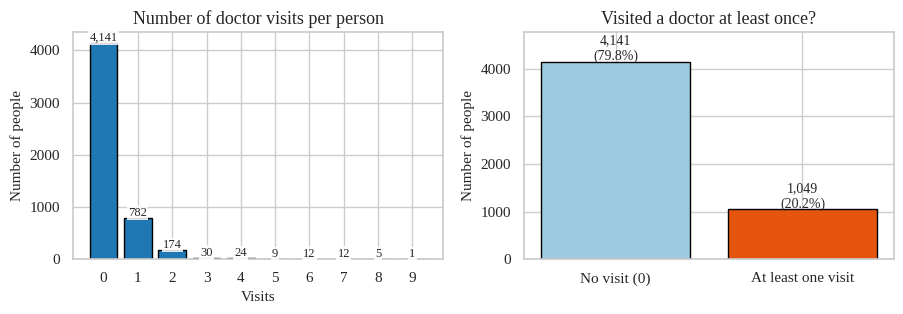

Mean visits: 0.3 | variance/mean: 2.11
Mean visits among those who visited: 1.49
People with 3+ visits: 93 -> share of all visits: 27.8 %


In [8]:
counts = data["visits"].value_counts().sort_index()
pct = (counts / len(data) * 100).round(2)
display(pd.DataFrame({"Count": counts, "Percent": pct}))

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.3))
bars = ax[0].bar(counts.index.astype(str), counts.values, color="#1F77B4", edgecolor="black")
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v + 40, f"{v:,}", ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.8))
ax[0].set_title("Number of doctor visits per person")
ax[0].set_xlabel("Visits")
ax[0].set_ylabel("Number of people")

vc = data["visited"].value_counts().sort_index()
b2 = ax[1].bar(["No visit (0)", "At least one visit"], vc.values, color=["#9ECAE1", "#E6550D"], edgecolor="black")
for b, v in zip(b2, vc.values):
    ax[1].text(b.get_x() + b.get_width() / 2, v + 40, f"{v:,}\n({v/len(data)*100:.1f}%)", ha="center", fontsize=10)
ax[1].set_ylim(0, vc.max() * 1.15)
ax[1].set_title("Visited a doctor at least once?")
ax[1].set_ylabel("Number of people")
plt.tight_layout()
save_fig("fig1_outcome")
plt.show()

print("Mean visits:", round(data["visits"].mean(), 2), "| variance/mean:", round(data["visits"].var() / data["visits"].mean(), 2))
print("Mean visits among those who visited:", round(data.loc[data.visited == 1, "visits"].mean(), 2))
print("People with 3+ visits:", (data.visits >= 3).sum(), "-> share of all visits:",
      round(data.loc[data.visits >= 3, "visits"].sum() / data["visits"].sum() * 100, 1), "%")

**Interpretation**
- **Fact:** 4,141 people (79.8%) had no visit; 1,049 (20.2%) had at least one. The mean is 0.30 visits and the maximum is 9.
- **Fact:** 93 people (1.8%) made 3 or more visits but account for 436 of the 1,566 visits (27.8%). A few heavy users carry a large share of all visits.
- Because most values are 0 and the variance (about 2.1 times the mean) is well above the mean, an average visit count describes almost nobody. Most comparisons below therefore use the **share who visited at least once**, with the mean visit count as a second view.

## 8. Age and income distribution

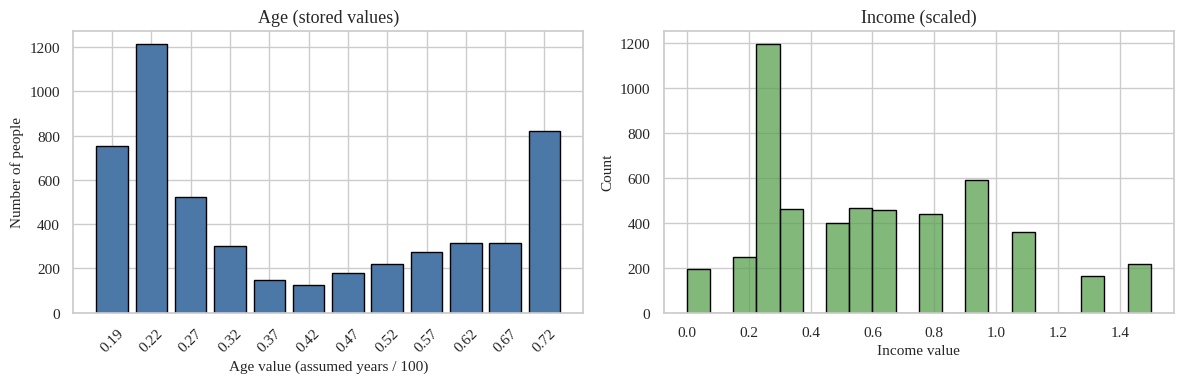

Mean age value: 0.406 | median: 0.32
Mean income: 0.583 | median: 0.55


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
age_counts = data["age"].value_counts().sort_index()
ax[0].bar(age_counts.index.astype(str), age_counts.values, color="#4C78A8", edgecolor="black")
ax[0].set_title("Age (stored values)")
ax[0].set_xlabel("Age value (assumed years / 100)")
ax[0].set_ylabel("Number of people")
ax[0].tick_params(axis="x", rotation=45)
sns.histplot(data["income"], bins=20, color="#59A14F", edgecolor="black", ax=ax[1])
ax[1].set_title("Income (scaled)")
ax[1].set_xlabel("Income value")
plt.tight_layout()
save_fig("fig3_age_income")
plt.show()
print("Mean age value:", round(data.age.mean(), 3), "| median:", data.age.median())
print("Mean income:", round(data.income.mean(), 3), "| median:", data.income.median())

**Interpretation:** age is concentrated in the youngest values (38% of records are 0.22 or below) with a second group at the oldest values (22% are 0.67 or above). Income is right-skewed: median 0.55, mean 0.58, maximum 1.5.

## 9. Profile of people who visited vs those who did not

,"No visit (n=4,141)","1+ visits (n=1,049)"
Average age value,0.39,0.47
Average income,0.60,0.52
Average illnesses,1.26,2.13
Average reduced-activity days,0.43,2.58
Average health score,1.02,1.99
% female,49.31,62.92
% private cover,44.39,43.85
% free cover (poor),4.88,1.91
% free cover (repat.),18.01,32.89
% nchronic,38.57,47.19


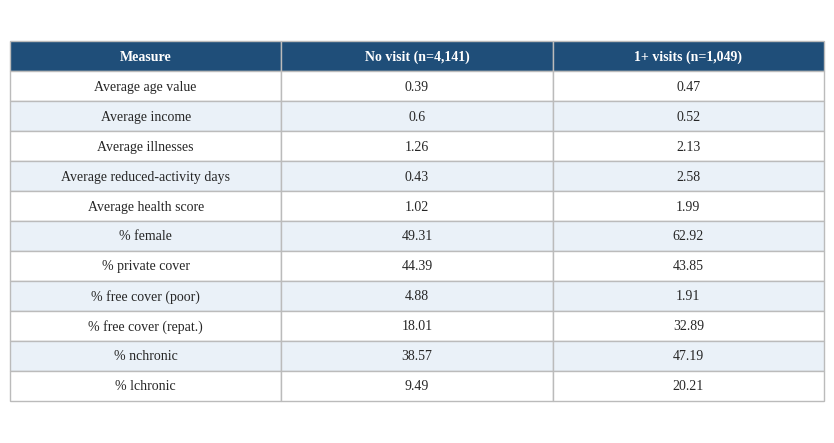

In [10]:
num = ["age", "income", "illness", "reduced", "health"]
flags = ["female", "private_n", "freepoor_n", "freerepat_n", "nchronic_n", "lchronic_n"]
nm = {"age": "Average age value", "income": "Average income", "illness": "Average illnesses",
      "reduced": "Average reduced-activity days", "health": "Average health score",
      "female": "% female", "private_n": "% private cover", "freepoor_n": "% free cover (poor)",
      "freerepat_n": "% free cover (repat.)", "nchronic_n": "% nchronic", "lchronic_n": "% lchronic"}
g = data.groupby("visited")
prof = pd.concat([g[num].mean().T, g[flags].mean().T * 100])
n0, n1 = (data.visited == 0).sum(), (data.visited == 1).sum()
prof.columns = [f"No visit (n={n0:,})", f"1+ visits (n={n1:,})"]
prof.index = [nm[i] for i in prof.index]
prof = prof.round(2)
display(prof)
table_image(prof.reset_index().rename(columns={"index": "Measure"}), "fig4_profile", fontsize=10, figsize=(8.5, 4.6))

**Interpretation (descriptive, not causal)**
- Visitors report more illness (2.13 vs 1.26), far more reduced-activity days (2.58 vs 0.43) and a worse health score (1.99 vs 1.02).
- Visitors are older (0.47 vs 0.39), more often female (62.9% vs 49.3%) and have lower income (0.52 vs 0.60).
- Private cover is almost identical in both groups (43.9% vs 44.4%). Free-poor cover is rarer among visitors (1.9% vs 4.9%); free-repatriation cover is more common (32.9% vs 18.0%).

## 10. Health indicators and doctor visits

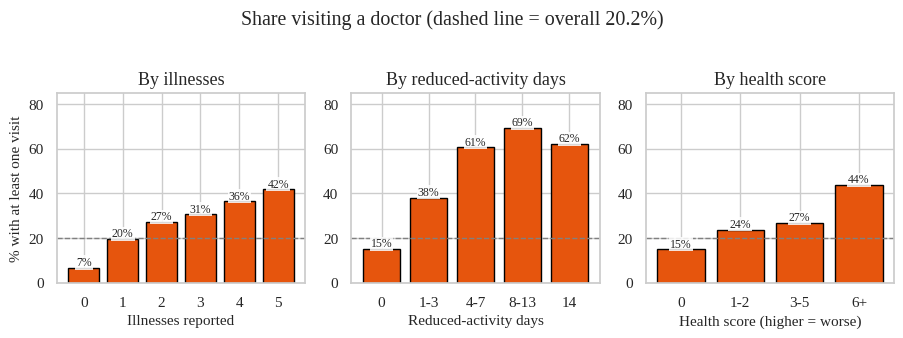

,n,rate
illness,,
0,1554,6.8
1,1638,19.6
2,946,27.3
3,542,30.6
4,274,36.5
5,236,41.9


,n,rate
reduced_band,,
0,4454,15.2
1-3,359,38.2
4-7,140,60.7
8-13,49,69.4
14,188,62.2


,n,rate
health_band,,
0,3026,15.0
1-2,1269,23.8
3-5,592,26.9
6+,303,43.9


Spearman illness vs visits: rho = 0.263, p = 1.2e-82
Spearman reduced vs visits: rho = 0.336, p = 8.4e-137
Spearman health vs visits: rho = 0.178, p = 5.2e-38


In [11]:
def rate_plot(ax, col, title, xlabel, show_n=True):
    t = data.groupby(col, observed=True).agg(n=("visited", "size"), rate=("visited", "mean"))
    t["rate"] *= 100
    bars = ax.bar(t.index.astype(str), t["rate"], color="#E6550D", edgecolor="black")
    for b, (r, n) in zip(bars, zip(t["rate"], t["n"])):
        ax.text(b.get_x() + b.get_width() / 2, r + 1, (f"{r:.0f}%\nn={n:,}" if show_n else f"{r:.0f}%"), ha="center", fontsize=8.5, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.8))
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1)
    ax.set_ylim(0, 85)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    return t

fig, ax = plt.subplots(1, 3, figsize=(9.2, 3.3))
t_ill = rate_plot(ax[0], "illness", "By illnesses", "Illnesses reported", show_n=False)
t_red = rate_plot(ax[1], "reduced_band", "By reduced-activity days", "Reduced-activity days", show_n=False)
t_hea = rate_plot(ax[2], "health_band", "By health score", "Health score (higher = worse)", show_n=False)
ax[0].set_ylabel("% with at least one visit")
fig.suptitle("Share visiting a doctor (dashed line = overall 20.2%)", y=1.02)
plt.tight_layout()
save_fig("fig5_health")
plt.show()
display(t_ill.round(1)); display(t_red.round(1)); display(t_hea.round(1))

for c in ["illness", "reduced", "health"]:
    r = stats.spearmanr(data[c], data["visits"])
    print(f"Spearman {c} vs visits: rho = {r.statistic:.3f}, p = {r.pvalue:.1e}")

**Interpretation**
- **Fact:** the share visiting rises steadily with illness count, from 6.8% with 0 illnesses to 41.9% with 5.
- **Fact:** the share visiting is 15.2% with no reduced-activity days and 38.2% to 69.4% for 1 to 13 days.
- **Fact:** the share visiting is 15.0% at health score 0 and 43.9% at score 6 or more.
- **Correlation (Spearman, visits count):** reduced days ρ = 0.34, illness ρ = 0.26, health score ρ = 0.18. All three are positive and highly significant (p < 1e-35), but modest: none explains most of the variation.
- The 188 records at 14 reduced days (62.2% visited) do not continue the climb of the 8-13 group (69.4%), consistent with the cap hypothesis in Section 5.

## 11. Gender, coverage and chronic-condition groups

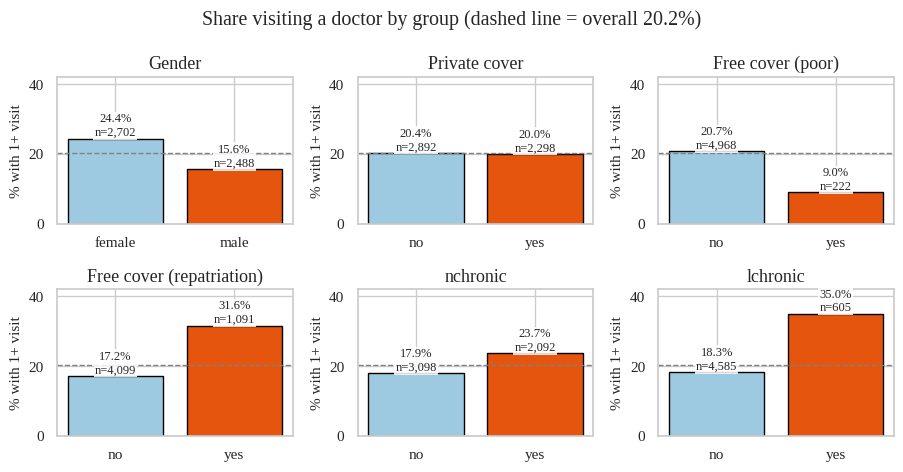

,Group (second bar),n,% visited,% visited (other),Mean visits,Mean (other),Chi-square p,Mann-Whitney p
0,Gender,"2,488",15.6%,24.4%,0.24,0.36,4.4e-15,6.3e-15
1,Private cover,"2,298",20.0%,20.4%,0.29,0.31,7.8e-01,7.6e-01
2,Free cover (poor),222,9.0%,20.7%,0.16,0.31,3.1e-05,2.5e-05
3,Free cover (repatriation),"1,091",31.6%,17.2%,0.47,0.26,7.1e-26,1.5e-25
4,nchronic,"2,092",23.7%,17.9%,0.35,0.27,4.4e-07,5.7e-07
5,lchronic,605,35.0%,18.3%,0.60,0.26,7.3e-22,1.2e-23


In [12]:
groups = [("gender", "Gender"), ("private", "Private cover"), ("freepoor", "Free cover (poor)"),
          ("freerepat", "Free cover (repatriation)"), ("nchronic", "nchronic"), ("lchronic", "lchronic")]
fig, axes = plt.subplots(2, 3, figsize=(9.2, 4.8))
rows = []
for ax, (c, label) in zip(axes.ravel(), groups):
    t = data.groupby(c).agg(n=("visited", "size"), rate=("visited", "mean"), mean_visits=("visits", "mean"))
    t["rate"] *= 100
    bars = ax.bar(t.index, t["rate"], color=["#9ECAE1", "#E6550D"], edgecolor="black")
    for b, (r, n) in zip(bars, zip(t["rate"], t["n"])):
        ax.text(b.get_x() + b.get_width() / 2, r + 0.8, f"{r:.1f}%\nn={n:,}", ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.8))
    ax.axhline(overall, color="grey", linestyle="--", linewidth=1)
    ax.set_ylim(0, 42)
    ax.set_title(label)
    ax.set_ylabel("% with 1+ visit")
    lo, hi = sorted(data[c].unique())
    p_chi = stats.chi2_contingency(pd.crosstab(data[c], data["visited"]))[1]
    p_mw = stats.mannwhitneyu(data.loc[data[c] == lo, "visits"], data.loc[data[c] == hi, "visits"])[1]
    rows.append([label, f"{t.loc[hi, 'n']:,}", f"{t.loc[hi, 'rate']:.1f}%", f"{t.loc[lo, 'rate']:.1f}%",
                 f"{t.loc[hi, 'mean_visits']:.2f}", f"{t.loc[lo, 'mean_visits']:.2f}", f"{p_chi:.1e}", f"{p_mw:.1e}"])
fig.suptitle("Share visiting a doctor by group (dashed line = overall 20.2%)")
plt.tight_layout()
save_fig("fig6_flags")
plt.show()

tests = pd.DataFrame(rows, columns=["Group (second bar)", "n", "% visited", "% visited (other)",
                                    "Mean visits", "Mean (other)", "Chi-square p", "Mann-Whitney p"])
display(tests)

In [13]:
# Context for the caution below: who is in the groups with the biggest raw gaps?
for c in ["freerepat", "freepoor", "lchronic"]:
    print(c)
    display(data.groupby(c)[["age", "income", "illness", "reduced", "health"]].mean().round(2))
print("Free-poor people who also have private cover:", ((data.freepoor == "yes") & (data.private == "yes")).sum())

freerepat


,age,income,illness,reduced,health
freerepat,,,,,
no,0.34,0.66,1.29,0.74,1.14
yes,0.65,0.30,1.97,1.33,1.50


freepoor


,age,income,illness,reduced,health
freepoor,,,,,
no,0.41,0.6,1.44,0.87,1.19
yes,0.25,0.3,1.26,0.77,1.80


lchronic


,age,income,illness,reduced,health
lchronic,,,,,
no,0.40,0.59,1.32,0.63,1.07
yes,0.47,0.52,2.27,2.58,2.34


Free-poor people who also have private cover: 0


**Interpretation** (second bar = *male* for gender, *yes* for every other group)
- **Fact:** women visited more: 24.4% vs 15.6% (p < 1e-14). Mean visits 0.36 vs 0.24.
- **Fact:** private cover shows no difference: 20.0% vs 20.4% (p = 0.78).
- **Fact:** free-poor cover: 9.0% vs 20.7% visited (p < 1e-4), but only 222 people, all without private cover.
- **Fact:** free-repatriation cover: 31.6% vs 17.2% (p < 1e-24).
- **Fact:** lchronic: 35.0% vs 18.3%, mean visits 0.60 vs 0.26 (p < 1e-20). nchronic: 23.7% vs 17.9%, a much smaller gap.
- Six tests were run; with a Bonferroni threshold of 0.05/6 ≈ 0.008 every result above stays significant except private cover.
- **Caution:** these are raw comparisons. People with free-repatriation cover are much older (0.65 vs 0.34) and have lower income (0.30 vs 0.66); the lchronic group reports far more illness (2.27 vs 1.32) and reduced days (2.58 vs 0.63). Section 14 checks how much of each gap survives adjustment.

## 12. Age and income bands

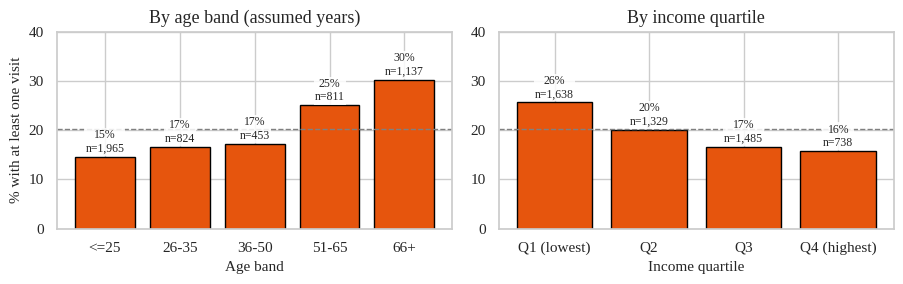

,n,rate
age_band,,
<=25,1965,14.7
26-35,824,16.6
36-50,453,17.2
51-65,811,25.0
66+,1137,30.2


,n,rate
income_band,,
Q1 (lowest),1638,25.6
Q2,1329,20.1
Q3,1485,16.6
Q4 (highest),738,15.7


Spearman age vs visits: rho = 0.148, p = 1.2e-26
Spearman income vs visits: rho = -0.093, p = 2.1e-11


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.0))
t_age = rate_plot(ax[0], "age_band", "By age band (assumed years)", "Age band")
t_inc = rate_plot(ax[1], "income_band", "By income quartile", "Income quartile")
ax[0].set_ylabel("% with at least one visit")
for a in ax:
    a.set_ylim(0, 40)
plt.tight_layout()
save_fig("fig7_age_income_rate")
plt.show()
display(t_age.round(1)); display(t_inc.round(1))
for c in ["age", "income"]:
    r = stats.spearmanr(data[c], data["visits"])
    print(f"Spearman {c} vs visits: rho = {r.statistic:.3f}, p = {r.pvalue:.1e}")

**Interpretation**
- **Fact:** the share visiting rises with age: 14.7% (<=25), 16.6%, 17.2%, 25.0% and 30.2% (66+). Spearman ρ = 0.15.
- **Fact:** it falls with income: 25.6% in the lowest quartile vs 15.7% in the highest. ρ = -0.09, a weak link.
- **Hypothesis:** the income gradient may reflect the age and health mix of lower-income groups rather than income itself (tested in Section 14).

## 13. Correlation analysis

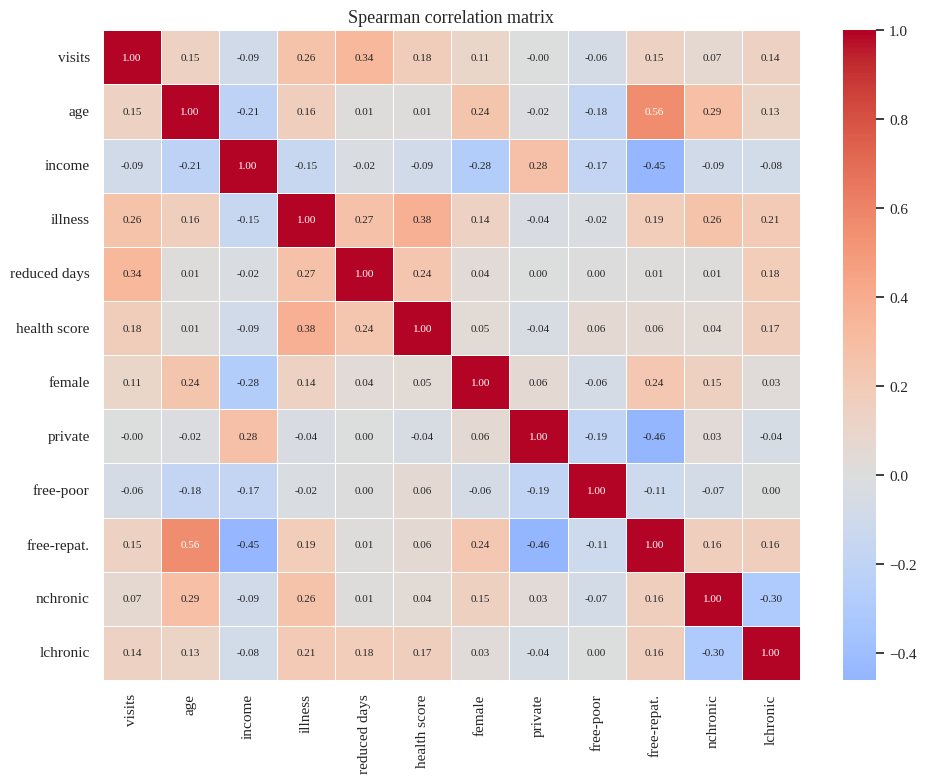

reduced        0.336
illness        0.263
health         0.178
age            0.148
freerepat_n    0.145
lchronic_n     0.139
female         0.108
nchronic_n     0.069
private_n     -0.004
freepoor_n    -0.059
income        -0.093
Name: visits, dtype: float64


In [15]:
cols = ["visits", "age", "income", "illness", "reduced", "health"] + flags
corr = data[cols].corr(method="spearman")
labels = ["visits", "age", "income", "illness", "reduced days", "health score",
          "female", "private", "free-poor", "free-repat.", "nchronic", "lchronic"]
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5,
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 8})
plt.title("Spearman correlation matrix")
plt.tight_layout()
save_fig("fig8_correlation")
plt.show()
print(corr["visits"].drop("visits").sort_values(ascending=False).round(3))

**Interpretation**
- **Correlation:** visits correlate most with reduced days (0.34), illness (0.26), health score (0.18), age (0.15), free-repatriation cover (0.15) and lchronic (0.14).
- The predictors also overlap: lchronic goes with illness, reduced days and health score; free-poor goes with low income and younger age. This overlap is why raw gaps can mislead. Section 14 tests them together.

## 14. Adjusted analysis: which associations remain?

,OR,low,high,p
Male (vs female),0.771,0.656,0.906,0.002
Private cover,1.297,1.065,1.579,0.010
Free cover (poor),0.502,0.301,0.838,0.008
Free cover (repat.),1.522,1.158,2.001,0.003
nchronic,1.100,0.920,1.315,0.298
lchronic,1.265,0.991,1.615,0.059
Age (+10 years),1.049,0.999,1.101,0.054
Income (+1 unit),0.946,0.746,1.199,0.646
Illnesses (+1),1.305,1.233,1.381,0.000
Reduced days (+1),1.171,1.144,1.199,0.000


Pseudo R-squared: 0.127 | n = 5190


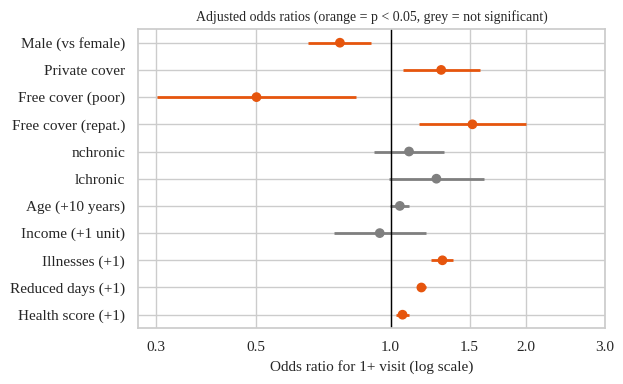

In [16]:
# Logistic regression: visited (0/1) on all variables together.
# Age is rescaled so one unit = 10 years (assumption: age = years/100).
data["age_10y"] = data["age"] * 10
model = smf.logit("visited ~ C(gender, Treatment('female')) + age_10y + income + illness + reduced + health"
                  " + C(private) + C(freepoor) + C(freerepat) + C(nchronic) + C(lchronic)", data).fit(disp=0)

names = {"C(gender, Treatment('female'))[T.male]": "Male (vs female)", "age_10y": "Age (+10 years)",
         "income": "Income (+1 unit)", "illness": "Illnesses (+1)", "reduced": "Reduced days (+1)",
         "health": "Health score (+1)", "C(private)[T.yes]": "Private cover", "C(freepoor)[T.yes]": "Free cover (poor)",
         "C(freerepat)[T.yes]": "Free cover (repat.)", "C(nchronic)[T.yes]": "nchronic", "C(lchronic)[T.yes]": "lchronic"}
res = pd.DataFrame({"OR": np.exp(model.params), "low": np.exp(model.conf_int()[0]),
                    "high": np.exp(model.conf_int()[1]), "p": model.pvalues}).drop("Intercept")
res.index = [names[i] for i in res.index]
display(res.round(3))
print("Pseudo R-squared:", round(model.prsquared, 3), "| n =", int(model.nobs))

plot = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.4, 4.0))
colors = ["#E6550D" if p < 0.05 else "#7F7F7F" for p in plot["p"]]
ax.hlines(range(len(plot)), plot["low"], plot["high"], color=colors, linewidth=2)
ax.scatter(plot["OR"], range(len(plot)), color=colors, zorder=3)
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 1.5, 2, 3])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_yticks(range(len(plot)))
ax.set_yticklabels(plot.index)
ax.set_xlabel("Odds ratio for 1+ visit (log scale)")
ax.set_title("Adjusted odds ratios (orange = p < 0.05, grey = not significant)", fontsize=10)
plt.tight_layout()
save_fig("fig9_adjusted")
plt.show()

**Interpretation**
- **Strong evidence (stays after adjustment):** illness (OR 1.31 per illness), reduced-activity days (OR 1.17 per day) and health score (OR 1.06 per point). These remain clearly significant (p < 0.001).
- **Stays:** being female (male OR 0.77, p = 0.002), free-repatriation cover (OR 1.52, p = 0.003) and free-poor cover (OR 0.50, p = 0.008; only 222 people).
- **Weakens:** lchronic falls from a raw 35.0% vs 18.3% to OR 1.27 (p = 0.059, not significant at 5%). **Hypothesis:** the chronic-limitation group visits more mainly because it is sicker on the other measures. Age is borderline (p = 0.054) and income disappears (p = 0.65).
- **Appears only after adjustment:** private cover has no raw gap but an adjusted OR of 1.30 (p = 0.010). Treat as a **correlation** needing caution: it is not visible in the raw data.
- **Fit:** pseudo R² = 0.13. Most of the variation in who visits is **not explained** by these variables.

## 15. Key findings summary

In [17]:
print(f"Total records: {len(data):,}")
print(f"No visit: {(data.visited == 0).sum():,} ({100 - overall:.1f}%) | 1+ visits: {(data.visited == 1).sum():,} ({overall:.1f}%)")
print("\nShare visiting by illness count (%):")
print((data.groupby('illness').visited.mean() * 100).round(1).to_dict())
print("\nAdjusted odds ratios:")
display(res.round(3))

Total records: 5,190
No visit: 4,141 (79.8%) | 1+ visits: 1,049 (20.2%)

Share visiting by illness count (%):
{0: 6.8, 1: 19.6, 2: 27.3, 3: 30.6, 4: 36.5, 5: 41.9}

Adjusted odds ratios:


,OR,low,high,p
Male (vs female),0.771,0.656,0.906,0.002
Private cover,1.297,1.065,1.579,0.010
Free cover (poor),0.502,0.301,0.838,0.008
Free cover (repat.),1.522,1.158,2.001,0.003
nchronic,1.100,0.920,1.315,0.298
lchronic,1.265,0.991,1.615,0.059
Age (+10 years),1.049,0.999,1.101,0.054
Income (+1 unit),0.946,0.746,1.199,0.646
Illnesses (+1),1.305,1.233,1.381,0.000
Reduced days (+1),1.171,1.144,1.199,0.000


1. **Fact:** 79.8% of people had no doctor visit; 1.8% made 3+ visits and account for 27.8% of all visits.
2. **Strong evidence:** illness count, reduced-activity days and health score are associated with more visits, in raw comparisons and after adjustment. The share visiting goes from 6.8% (0 illnesses) to 41.9% (5).
3. **Strong evidence:** women visit more than men (24.4% vs 15.6%); the gap persists after adjustment.
4. **Correlation:** free-repatriation cover goes with more visits (31.6% vs 17.2%; adjusted OR 1.52). **Hypothesis:** this group is older and sicker; the data cannot separate the programme from its members.
5. **Correlation:** free-poor cover goes with fewer visits (9.0% vs 20.7%), but the group is small (222), younger and lower income.
6. **Hypothesis:** the raw chronic-limitation gap (35.0% vs 18.3%) is mostly explained by greater illness; it is no longer significant after adjustment (p = 0.059).
7. **Fact:** private cover shows no raw difference in visits (20.0% vs 20.4%).
8. Age and income show modest raw links (older more, richer fewer) that weaken once health is accounted for.
9. **Limitation:** the model explains little (pseudo R² 0.13). Who visits depends mostly on things this dataset does not record.

## 16. Limitations and next steps
**Limitations**
- Observational data from a single snapshot: associations, not causes.
- The period covered by `visits` is not stated in the guide, and age and income are scaled with unconfirmed units.
- Small groups (free-poor, n = 222) give wide uncertainty.
- Visit counts are mostly zeros, so means are unstable; the yes/no outcome loses the difference between 1 and 9 visits.
- No data on cost, type of illness or access to doctors.

**Next steps**
- Fit a count model suited to many zeros (zero-inflated Poisson or negative binomial).
- Add cost, diagnosis and access-to-care variables.
- Confirm the age, income and `reduced` definitions with the data owner.
- Build a dashboard so planners can filter by group.